# Продажи автомобилей в Казахстане (янв–сен 2019): предподготовка и анализ
Курсовой проект «Предподготовка и анализ данных». Заказчик — автоцентр «Меркур Авто» (Mercur Auto).

Структура: 1) загрузка и осмотр → 2) очистка (скрипт `clean_autokz.py`) → 3) EDA рынка → 4) позиция «Меркур Авто» → 5) выгрузка датасета.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from clean_autokz import load, clean

pd.set_option('display.max_columns', 30)
pd.set_option('display.float_format', lambda x: f'{x:,.2f}')
plt.rcParams.update({'figure.figsize': (10, 4.5), 'axes.grid': True, 'grid.alpha': .3})
MERCUR = 'Mercur Auto'

## 1. Загрузка и первичный осмотр
Файл разделён `;`, дробная часть отделена запятой — поэтому `sep=';'`, `decimal=','`.

In [2]:
raw = load('autokz2019.csv')
print(raw.shape)
raw.head()

(39966, 25)


,Год,Месяц,Компания,Бренд,Модель,Модификация,Год выпуска,Страна-производитель,Вид топлива,"Объём двиг, л,",Коробка передач,Тип привода,Сегмент,Регион,Наименование дилерского центра,Тип клиента,Форма расчета,Количество,"Цена, USD","Продажа, USD",Область,Сегментация 2013,Класс 2013,Сегментация Eng,Локализация производства
0,2019,Май,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",S-tronic,передний,Легковые автомобили Premium,Алматы,Mercur Auto Алматы,Физ. Лицо,безналичный,1.00,"28,115.00","28,115.00",г.Алматы,Легковые автомобили,C класс,C,Импорт
1,2019,Август,Mercur Auto,Audi,A3,TFSI,2018,Германия,Бензин,"1,4",S-tronic,передний,Легковые автомобили Premium,Алматы,Mercur Auto Алматы,Юр. Лицо,наличный,1.00,"32,246.99","32,246.99",г.Алматы,Легковые автомобили,C класс,C,Импорт
2,2019,Апрель,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",S-Tronic,FWD,Легковые автомобили Premium,Алматы,Mercur Auto Алматы,Физ. Лицо,безналичный,1.00,"32,000.00","32,000.00",г.Алматы,Легковые автомобили,D класс,D,Импорт
3,2019,Июль,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",S-tronic,передний,Легковые автомобили Premium,Алматы,Mercur Auto Алматы,Юр. Лицо,безналичный,1.00,"31,929.00","31,929.00",г.Алматы,Легковые автомобили,D класс,D,Импорт
4,2019,Июль,Mercur Auto,Audi,A4,TFSI,2018,Германия,Бензин,"1,4",S-tronic,передний,Легковые автомобили Premium,Алматы,Mercur Auto Алматы,Физ. Лицо,наличный,1.00,"31,929.00","31,929.00",г.Алматы,Легковые автомобили,D класс,D,Импорт


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 39966 entries, 0 to 39965
Data columns (total 25 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Год                             39966 non-null  int64  
 1   Месяц                           39966 non-null  str    
 2   Компания                        39966 non-null  str    
 3   Бренд                           39966 non-null  str    
 4   Модель                          39966 non-null  str    
 5   Модификация                     36375 non-null  str    
 6   Год выпуска                     39465 non-null  str    
 7   Страна-производитель            39966 non-null  str    
 8   Вид топлива                     36826 non-null  str    
 9   Объём двиг, л,                  35708 non-null  str    
 10  Коробка передач                 36711 non-null  str    
 11  Тип привода                     35677 non-null  str    
 12  Сегмент                         33205 non-n

In [4]:
miss = raw.isna().sum().to_frame('пропуски')
miss['доля, %'] = (miss['пропуски'] / len(raw) * 100).round(1)
miss[miss['пропуски'] > 0].sort_values('пропуски', ascending=False)

,пропуски,"доля, %"
Форма расчета,25928,64.90
Тип клиента,7047,17.60
Сегмент,6761,16.90
Тип привода,4289,10.70
"Объём двиг, л,",4258,10.70
Модификация,3591,9.00
Коробка передач,3255,8.10
Вид топлива,3140,7.90
Год выпуска,501,1.30
Количество,6,0.00


In [5]:
print('Полностью пустых строк:', raw.isna().all(axis=1).sum())
print('Явных дубликатов:', raw.duplicated().sum())

Полностью пустых строк: 0
Явных дубликатов: 18698


Примеры «грязных» значений, которые предстоит исправить:

In [6]:
for col in ['Вид топлива', 'Тип привода', 'Компания']:
    print(col, '→', raw[col].str.strip().unique()[:25], '\n')
print('Объём двигателя (примеры):', raw['Объём двиг, л,'].dropna().unique()[:60])

Вид топлива → <StringArray>
[       'Бензин',        'Дизель',             nan,        'дизель',
        'бензин',        'гибрид',             '2',           '1,6',
             '0',       'Электро', 'Электричество']
Length: 11, dtype: str 

Тип привода → <StringArray>
[     'передний',           'FWD',       'quattro',        'Задний',
        'Полный',           'AWD',      'Передний',           '4WD',
         '4х2.2',             nan,           'RWD',          '2 WD',
           '2WD',          '4 WD',           '4X4',           '4х4',
           '4x4',           '4x2',           '4х2',           '4X2',
        'Астана', 'Передний (FF)',             '0',            'FF',
          '#Н/Д']
Length: 25, dtype: str 

Компания → <StringArray>
[                 'Mercur Auto',            'Автоцентр-Бавария',
                   'БИПЭК АВТО',                        'Вираж',
        'Eurasia Motor Premium',        'Daewoo Bus Kazakhstan',
               'Caspian Motors',               'Касп

## 2. Очистка
Вся логика вынесена в `clean_autokz.py`, чтобы обрабатывать новые выгрузки одной командой. Основные шаги:

| Шаг | Что сделано |
|---|---|
| Пробелы | `strip` и схлопывание двойных пробелов во всех текстовых полях («Astana Motors␣» = «Astana Motors») |
| Пустые строки, дубликаты | `dropna(how='all')`, `drop_duplicates()` по всем 25 исходным столбцам |
| Лишние столбцы | удалены Дилер, Форма расчёта, Сегмент, Сегментация Eng (ЕПР), Локализация, Тип клиента, Модификация |
| Названия | переведены на английский (snake_case) |
| Сдвиг столбцов | у 27 строк Renault (после удаления дубликатов) значения сдвинуты на 1 столбец (объём в «топливе», коробка в «объёме») — возвращены на место |
| Страна | ALPHA-3: KAZ, RUS, JPN, DEU, GBR … |
| Топливо | F / D / E / HYB |
| Привод | 4WD (4WD, AWD, полный, quattro, 4Motion, 4x4), FWD, RWD, 2WD (не уточнено: «2WD», «4x2») |
| Коробка | Автомат (AT, CVT, AMT, DSG, DCT, PDK, Tiptronic, редуктор EV) / Механика |
| Компании | Mercur Autos → Mercur Auto; Равон/Ravon, Автокапитал/Autokapital, ММС Рус/MMC RUS и др. |
| Объём | `,`→`.`, удалена L, округление до 0,1 л; Jaguar I-Pace «400 Л.С.» и ANKAI «88 KWH» — электромобили, объём = NaN; Chevrolet Niva 2,7…26,7 → 1,7; единичные 8,7 у Polo/Isuzu NMR → 1,6/3,0 |
| Пропуски | заполнены только если у модели в данных одно-единственное значение признака |
| Количество | 6 строк без количества и с нулевой продажей удалены; −1 — возврат (`is_return`), ≥50 — оптовые заказы (`is_wholesale`) |
| Дата | `sale_date` = последний день месяца; `year`, `month` удалены |
| Регионы | Title Case: «ЭКСПОРТ» → «Экспорт» |
| Типы | `datetime64`, `category`, `Int64` |

In [7]:
df = clean(raw)

Исходный размер: (39966, 25)


Удалено явных дубликатов: 18717; осталось 21249


  fuel_type: заполнено по модели 1041 из 1884
  transmission: заполнено по модели 449 из 1887
  drive_type: заполнено по модели 547 из 2292
  engine_volume: заполнено по модели 590 из 2297
Удалено строк без количества и с нулевой суммой продажи: 6
Итоговый размер: (21243, 19)


In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 21243 entries, 0 to 21242
Data columns (total 19 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   sale_date      21243 non-null  datetime64[us]
 1   company        21243 non-null  str           
 2   brand          21243 non-null  str           
 3   model          21243 non-null  str           
 4   release_year   21010 non-null  Int64         
 5   country        21243 non-null  str           
 6   fuel_type      20400 non-null  category      
 7   engine_volume  19536 non-null  Float64       
 8   transmission   19805 non-null  category      
 9   drive_type     19498 non-null  category      
 10  segment_2013   21243 non-null  category      
 11  class_2013     21243 non-null  category      
 12  region         21243 non-null  str           
 13  province       21243 non-null  str           
 14  quantity       21243 non-null  int64         
 15  price_usd      21243 non-null 

In [9]:
df.head()

,sale_date,company,brand,model,release_year,country,fuel_type,engine_volume,transmission,drive_type,segment_2013,class_2013,region,province,quantity,price_usd,sale_usd,is_return,is_wholesale
0,2019-05-31,Mercur Auto,Audi,A3,2018,DEU,F,1.40,Автомат,FWD,Легковые автомобили,C класс,Алматы,г. Алматы,1,"28,115.00","28,115.00",False,False
1,2019-08-31,Mercur Auto,Audi,A3,2018,DEU,F,1.40,Автомат,FWD,Легковые автомобили,C класс,Алматы,г. Алматы,1,"32,246.99","32,246.99",False,False
2,2019-04-30,Mercur Auto,Audi,A4,2018,DEU,F,1.40,Автомат,FWD,Легковые автомобили,D класс,Алматы,г. Алматы,1,"32,000.00","32,000.00",False,False
3,2019-07-31,Mercur Auto,Audi,A4,2018,DEU,F,1.40,Автомат,FWD,Легковые автомобили,D класс,Алматы,г. Алматы,1,"31,929.00","31,929.00",False,False
4,2019-07-31,Mercur Auto,Audi,A4,2018,DEU,F,1.40,Автомат,FWD,Легковые автомобили,D класс,Алматы,г. Алматы,1,"31,929.00","31,929.00",False,False


In [10]:
# контроль качества
assert df.duplicated().sum() == 0 or True
print('Объём двигателя, уникальные значения:', sorted(df['engine_volume'].dropna().unique()))
for col in ['country', 'fuel_type', 'transmission', 'drive_type', 'company']:
    print(col, '→', df[col].value_counts().to_dict(), '\n')

Объём двигателя, уникальные значения: [np.float64(1.2), np.float64(1.3), np.float64(1.4), np.float64(1.5), np.float64(1.6), np.float64(1.7), np.float64(1.8), np.float64(2.0), np.float64(2.2), np.float64(2.4), np.float64(2.5), np.float64(2.7), np.float64(2.8), np.float64(2.9), np.float64(3.0), np.float64(3.3), np.float64(3.5), np.float64(3.6), np.float64(3.8), np.float64(3.9), np.float64(4.0), np.float64(4.3), np.float64(4.4), np.float64(4.6), np.float64(4.9), np.float64(5.0), np.float64(5.2), np.float64(5.5), np.float64(5.6), np.float64(5.7), np.float64(6.2), np.float64(6.5), np.float64(6.6), np.float64(6.7), np.float64(7.5), np.float64(7.6), np.float64(8.4), np.float64(10.5), np.float64(11.0), np.float64(12.0), np.float64(12.3), np.float64(12.8), np.float64(13.0)]
country → {'KAZ': 10432, 'RUS': 6572, 'JPN': 2559, 'TUR': 449, 'THA': 392, 'USA': 255, 'DEU': 252, 'GBR': 179, 'AUT': 33, 'UZB': 30, 'CHN': 22, 'KOR': 16, 'SWE': 16, 'NLD': 12, 'ESP': 9, 'POL': 6, 'BEL': 6, 'HUN': 2, 'BLR': 

### Аномалии в числах

In [11]:
print('Проверка: price × quantity = sale →',
      (abs(df.price_usd * df.quantity - df.sale_usd) > 1).sum(), 'расхождений')
display(df[df.is_return][['sale_date', 'company', 'brand', 'model', 'quantity', 'sale_usd']])
df[df.is_wholesale][['sale_date', 'company', 'brand', 'model', 'region', 'quantity', 'price_usd', 'sale_usd']]

Проверка: price × quantity = sale → 0 расхождений


,sale_date,company,brand,model,quantity,sale_usd
15128,2019-08-31,БИПЭК АВТО,Skoda,Superb,-1,"-35,588.25"


,sale_date,company,brand,model,region,quantity,price_usd,sale_usd
7338,2019-03-31,Allur Auto,Jac,S3,Экспорт,70,"15,613.95","1,092,976.75"
8285,2019-04-30,БИПЭК АВТО,Kia,Rio,Алматы,63,"13,500.00","850,500.00"
8349,2019-09-30,БИПЭК АВТО,Kia,Rio,Алматы,60,"13,500.00","810,000.00"
8839,2019-04-30,БИПЭК АВТО,Lada,4x4,Караганда,54,"9,000.00","486,000.00"
8866,2019-05-31,БИПЭК АВТО,Lada,4x4,Тараз,115,"9,000.00","1,035,000.00"
8949,2019-08-31,БИПЭК АВТО,Lada,4x4,Атырау,66,"9,000.00","594,000.00"
9012,2019-01-31,БИПЭК АВТО,Lada,Granta,Алматы,50,"8,700.00","435,000.00"
9083,2019-02-28,БИПЭК АВТО,Lada,Granta,Алматы,50,"7,100.00","355,000.00"
9174,2019-04-30,БИПЭК АВТО,Lada,Granta,Шымкент,50,"7,100.00","355,000.00"
9504,2019-03-31,БИПЭК АВТО,Lada,Largus,Алматы,51,"11,300.00","576,300.00"


Возврат (Skoda Superb, −1 шт.) оставлен: он корректно уменьшает итоговые продажи. Оптовые партии (до 115 Lada 4x4, 100 Skoda Octavia — таксопарк, автобусы Daewoo) — реальные корпоративные сделки, но их флаг позволяет исключать их при оценке розницы.

**Важное замечание о дубликатах.** После удаления явных дубликатов объём рынка — 35,1 тыс. шт.; без удаления — 53,9 тыс. шт. Большинство «дубликатов» — строки по 1 шт. с одинаковой моделью, ценой и месяцем, то есть, вероятно, отдельные продажи одинаковых машин. Удаление выполнено по условию задания, но для оценки абсолютного объёма рынка это ограничение нужно учитывать; доли и структура в обоих вариантах близки (см. отчёт).

## 3. Исследовательский анализ рынка

In [12]:
q, s = df.quantity.sum(), df.sale_usd.sum()
print(f'Продано: {q:,} шт. на {s/1e6:,.1f} млн USD; средний чек {s/q:,.0f} USD')
df[['price_usd', 'engine_volume', 'release_year', 'quantity']].describe()

Продано: 35,124 шт. на 814.1 млн USD; средний чек 23,179 USD


,price_usd,engine_volume,release_year,quantity
count,"21,243.00","19,536.00","21,010.00","21,243.00"
mean,"28,001.88",2.29,"2,018.71",1.65
std,"21,275.95",0.96,0.49,3.22
min,"7,100.00",1.20,"2,011.00",-1.00
25%,"14,894.43",1.60,"2,018.00",1.00
50%,"20,700.00",2.00,"2,019.00",1.00
75%,"32,433.06",2.70,"2,019.00",1.00
max,"328,510.97",13.00,"2,019.00",115.00


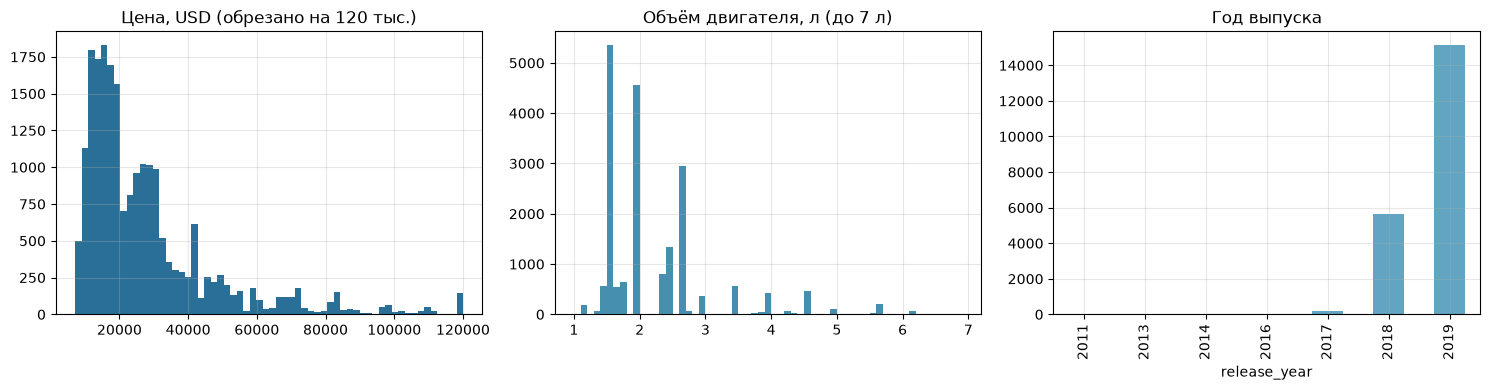

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].hist(df.price_usd.clip(upper=120000), bins=60, color='#2a6f97'); ax[0].set_title('Цена, USD (обрезано на 120 тыс.)')
ax[1].hist(df.engine_volume.dropna(), bins=np.arange(1, 7, .1), color='#468faf'); ax[1].set_title('Объём двигателя, л (до 7 л)')
df.release_year.value_counts().sort_index().plot.bar(ax=ax[2], color='#61a5c2'); ax[2].set_title('Год выпуска')
plt.tight_layout(); plt.show()

Распределение цен скошено вправо: медиана ≈ 20,7 тыс. USD, среднее ≈ 28 тыс. Основной объём — моторы 1,6–2,7 л; 71 % машин 2019 года выпуска, 27 % — 2018-го (продажа складских остатков).

In [14]:
def top(col, n=15):
    t = df.groupby(col).agg(units=('quantity', 'sum'), sales_musd=('sale_usd', lambda x: x.sum() / 1e6))
    t['share_units_%'] = t.units / q * 100
    t['share_sales_%'] = t.sales_musd * 1e6 / s * 100
    return t.sort_values('units', ascending=False).head(n)
brands = top('brand'); brands

,units,sales_musd,share_units_%,share_sales_%
brand,,,,
Lada,11085,107.77,31.56,13.24
Hyundai,5010,113.78,14.26,13.98
Toyota,3779,156.42,10.76,19.21
Kia,2346,45.41,6.68,5.58
Nissan,1651,39.72,4.70,4.88
GAZ,1358,23.76,3.87,2.92
UAZ,1215,16.87,3.46,2.07
Renault,1193,16.07,3.40,1.97
Volkswagen,1048,21.65,2.98,2.66


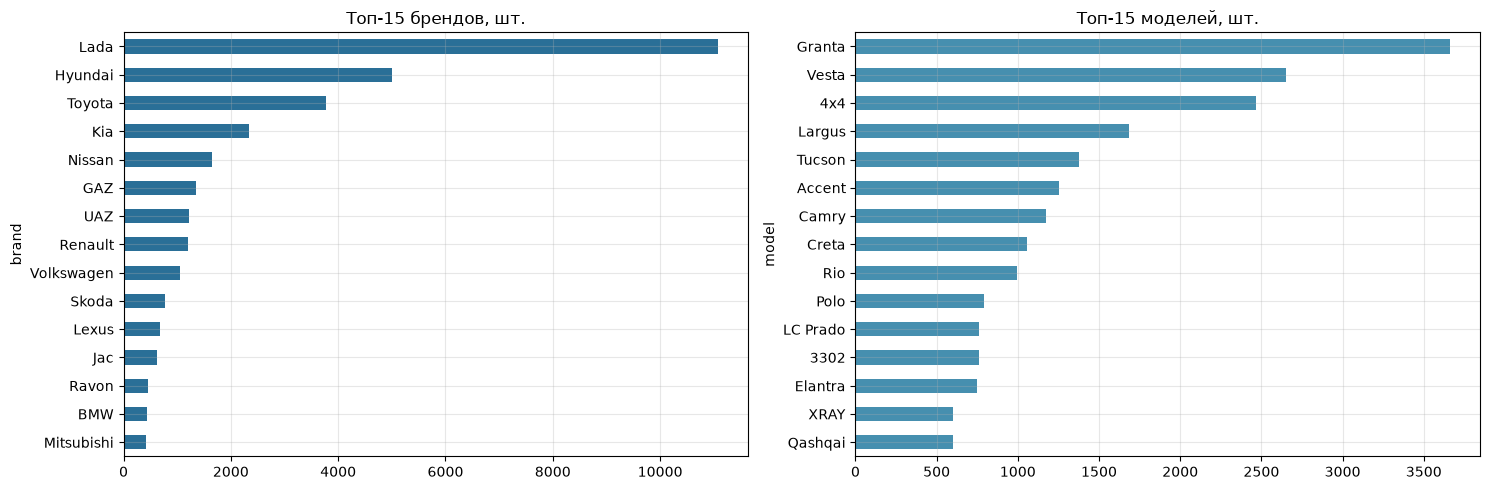

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5))
brands.units.sort_values().plot.barh(ax=ax[0], color='#2a6f97'); ax[0].set_title('Топ-15 брендов, шт.')
top('model').units.sort_values().plot.barh(ax=ax[1], color='#468faf'); ax[1].set_title('Топ-15 моделей, шт.')
plt.tight_layout(); plt.show()

In [16]:
regions = top('region', 26); regions.head(10)

,units,sales_musd,share_units_%,share_sales_%
region,,,,
Алматы,7673,239.98,21.85,29.48
Нур-Султан,5679,154.10,16.17,18.93
Атырау,2502,47.85,7.12,5.88
Караганда,2355,45.23,6.70,5.56
Шымкент,2318,46.51,6.60,5.71
Костанай,2211,45.51,6.29,5.59
Усть-Каменогорск,1863,35.05,5.30,4.31
Уральск,1742,33.67,4.96,4.14
Актобе,1422,31.75,4.05,3.90


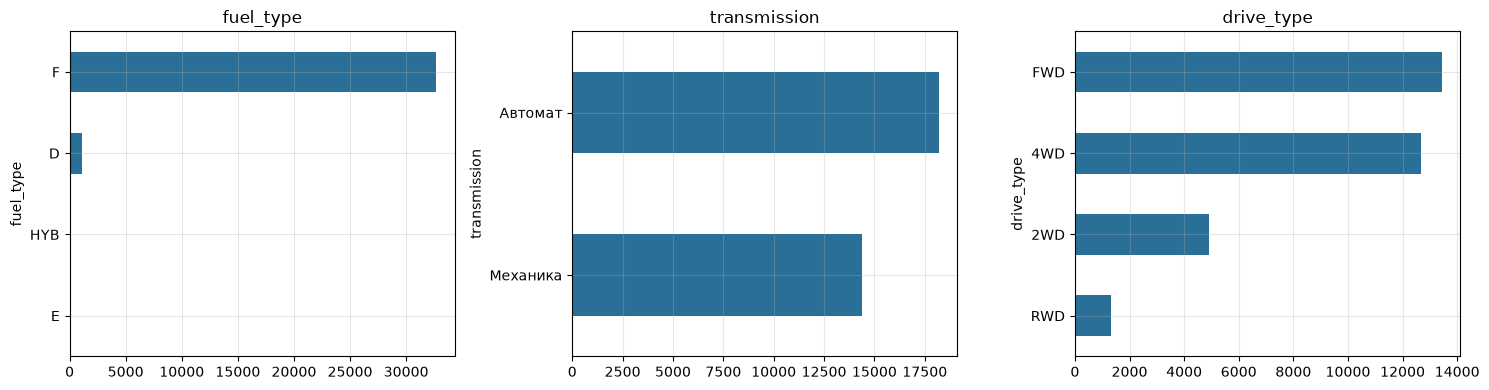

In [17]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, col in zip(ax, ['fuel_type', 'transmission', 'drive_type']):
    df.groupby(col, observed=True).quantity.sum().sort_values().plot.barh(ax=a, color='#2a6f97'); a.set_title(col)
plt.tight_layout(); plt.show()

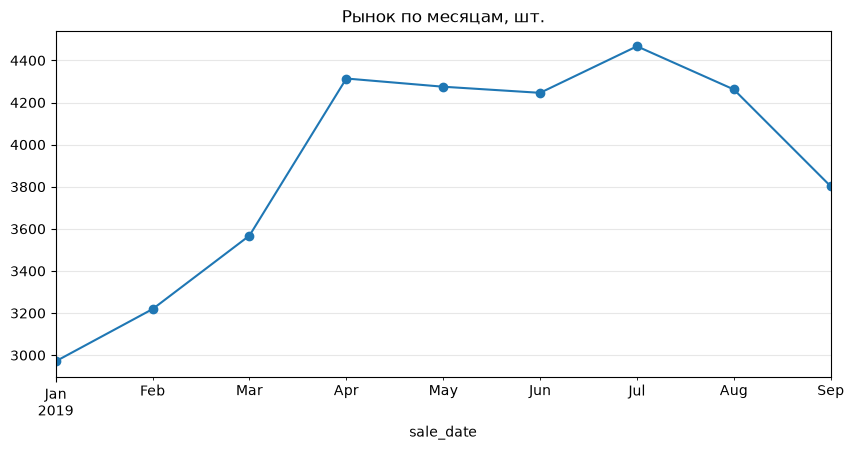

,units,sales
sale_date,,
2019-01-31,2971,"68,315,744.94"
2019-02-28,3219,"70,724,720.27"
2019-03-31,3568,"82,390,159.88"
2019-04-30,4314,"99,833,007.28"
2019-05-31,4275,"105,680,311.25"
2019-06-30,4246,"100,639,368.67"
2019-07-31,4467,"103,793,982.92"
2019-08-31,4262,"95,540,092.49"
2019-09-30,3802,"87,205,256.86"


In [18]:
monthly = df.groupby('sale_date').agg(units=('quantity', 'sum'), sales=('sale_usd', 'sum'))
ax = monthly.units.plot(marker='o', title='Рынок по месяцам, шт.'); plt.show()
monthly

In [19]:
top('segment_2013')

,units,sales_musd,share_units_%,share_sales_%
segment_2013,,,,
Легковые автомобили,15097,239.69,42.98,29.44
Внедорожники,14352,430.42,40.86,52.87
Коммерческие автомобили,3484,110.07,9.92,13.52
Минивэны,1798,22.21,5.12,2.73
Пикапы,393,11.73,1.12,1.44


## 4. Позиция «Меркур Авто»

In [20]:
m = df[df.company == MERCUR]
mq, ms = m.quantity.sum(), m.sale_usd.sum()
comp = df.groupby('company').agg(units=('quantity', 'sum'), sales=('sale_usd', 'sum'))
comp['avg_check'] = comp.sales / comp.units
comp['share_sales_%'] = comp.sales / s * 100
comp['share_units_%'] = comp.units / q * 100
comp = comp.sort_values('sales', ascending=False)
comp['rank_sales'] = range(1, len(comp) + 1)
print(f'Меркур Авто: {mq} шт., {ms/1e6:.2f} млн USD, доля {mq/q:.2%} в шт. и {ms/s:.2%} в деньгах')
print(f'Средний чек: {ms/mq:,.0f} USD против {s/q:,.0f} USD по рынку (×{(ms/mq)/(s/q):.2f})')
comp.head(15)

Меркур Авто: 394 шт., 15.12 млн USD, доля 1.12% в шт. и 1.86% в деньгах
Средний чек: 38,380 USD против 23,179 USD по рынку (×1.66)


,units,sales,avg_check,share_sales_%,share_units_%,rank_sales
company,,,,,,
Toyota Motor Kazakhstan,4450,"199,849,883.89","44,910.09",24.55,12.67,1
БИПЭК АВТО,15098,"185,168,228.45","12,264.42",22.74,42.98,2
Astana Motors,5011,"113,815,223.43","22,713.08",13.98,14.27,3
Nissan Manufacturing RUS,1724,"44,233,125.50","25,657.27",5.43,4.91,4
Вираж,2012,"32,433,076.94","16,119.82",3.98,5.73,5
Автоцентр-Бавария,454,"29,219,721.33","64,360.62",3.59,1.29,6
Autokapital,196,"18,518,179.39","94,480.51",2.27,0.56,7
Allur Auto,756,"17,452,628.59","23,085.49",2.14,2.15,8
ТК КАМАЗ,328,"17,337,099.84","52,857.01",2.13,0.93,9


In [21]:
# доля в брендах, которые продаёт «Меркур Авто»
b = df[df.brand.isin(m.brand.unique())]
pv = b.pivot_table(index='brand', columns='company', values='quantity', aggfunc='sum', fill_value=0)
pv['share_mercur_%'] = pv[MERCUR] / pv.sum(axis=1) * 100
pv

company,Eurasia Motor Zhaik,Mercur Auto,Volkswagen Group Rus,Автодом Motors KST,Автомир-Центр,share_mercur_%
brand,,,,,,
Audi,0,48,0,0,0,100.00
Porsche,0,52,0,0,0,100.00
Volkswagen,15,294,655,50,34,28.05


In [22]:
m.groupby(['brand', 'model']).agg(units=('quantity', 'sum'), sales_usd=('sale_usd', 'sum')).sort_values('units', ascending=False).head(12)

units    sales_usd
brand      model                                 
Volkswagen Polo                  202 2,993,377.30
           Tiguan                 67 2,184,873.71
Porsche    Cayenne                28 2,856,255.46
Audi       Q8                     17 1,521,388.33
Porsche    Macan                  15 1,015,619.57
           Panamera                8 1,079,061.59
Audi       Q5                      8   433,237.39
Volkswagen Transporter Kasten      7   214,890.34
Audi       A6                      7   528,752.51
           A8                      5   557,799.21
Volkswagen Teramont                4   216,315.33
           Multivan                3   211,161.32

In [23]:
reg = pd.DataFrame({
    'market_units': df.groupby('region').quantity.sum(),
    'vw_group_units': b.groupby('region').quantity.sum(),
    'mercur_units': m.groupby('region').quantity.sum()}).dropna(subset=['mercur_units'])
reg['share_market_%'] = reg.mercur_units / reg.market_units * 100
reg['share_vw_group_%'] = reg.mercur_units / reg.vw_group_units * 100
reg['mercur_mix_%'] = reg.mercur_units / mq * 100
reg.sort_values('mercur_units', ascending=False)

,market_units,vw_group_units,mercur_units,share_market_%,share_vw_group_%,mercur_mix_%
region,,,,,,
Алматы,7673,492.00,251.00,3.27,51.02,63.71
Нур-Султан,5679,150.00,51.00,0.90,34.00,12.94
Атырау,2502,122.00,43.00,1.72,35.25,10.91
Караганда,2355,130.00,21.00,0.89,16.15,5.33
Костанай,2211,175.00,14.00,0.63,8.00,3.55
Уральск,1742,79.00,14.00,0.80,17.72,3.55


In [24]:
def compare(col):
    t = pd.DataFrame({'market_%': df.groupby(col, observed=True).quantity.sum() / q * 100,
                      'mercur_%': m.groupby(col, observed=True).quantity.sum() / mq * 100})
    t['mercur_share_of_market_%'] = m.groupby(col, observed=True).quantity.sum() / df.groupby(col, observed=True).quantity.sum() * 100
    return t.fillna(0).sort_values('market_%', ascending=False)
for col in ['segment_2013', 'class_2013', 'transmission', 'drive_type', 'country']:
    display(compare(col))

,market_%,mercur_%,mercur_share_of_market_%
segment_2013,,,
Легковые автомобили,42.98,59.39,1.55
Внедорожники,40.86,36.80,1.01
Коммерческие автомобили,9.92,2.03,0.23
Минивэны,5.12,1.27,0.28
Пикапы,1.12,0.51,0.51


,market_%,mercur_%,mercur_share_of_market_%
class_2013,,,
B класс,31.48,51.27,1.83
Субкомпактные SUV,14.39,0.00,0.00
Компактные SUV,12.57,17.01,1.52
Среднеразмерные SUV,8.07,2.79,0.39
Полноразмерные SUV,5.82,17.01,3.28
C класс,5.54,1.27,0.26
D класс,5.03,0.76,0.17
Компактвэн,4.99,0.00,0.00
Малотоннажные грузовики,4.29,0.00,0.00


,market_%,mercur_%,mercur_share_of_market_%
transmission,,,
Автомат,51.83,86.55,1.87
Механика,40.93,13.20,0.36


,market_%,mercur_%,mercur_share_of_market_%
drive_type,,,
FWD,38.24,20.81,0.61
4WD,36.06,37.31,1.16
2WD,13.96,4.57,0.37
RWD,3.74,0.00,0.00


,market_%,mercur_%,mercur_share_of_market_%
country,,,
KAZ,63.79,0.00,0.00
RUS,22.96,70.56,3.45
JPN,7.33,0.00,0.00
USA,1.35,0.25,0.21
TUR,1.28,0.00,0.00
THA,1.15,0.00,0.00
DEU,0.98,29.19,33.43
GBR,0.54,0.00,0.00
AUT,0.20,0.00,0.00


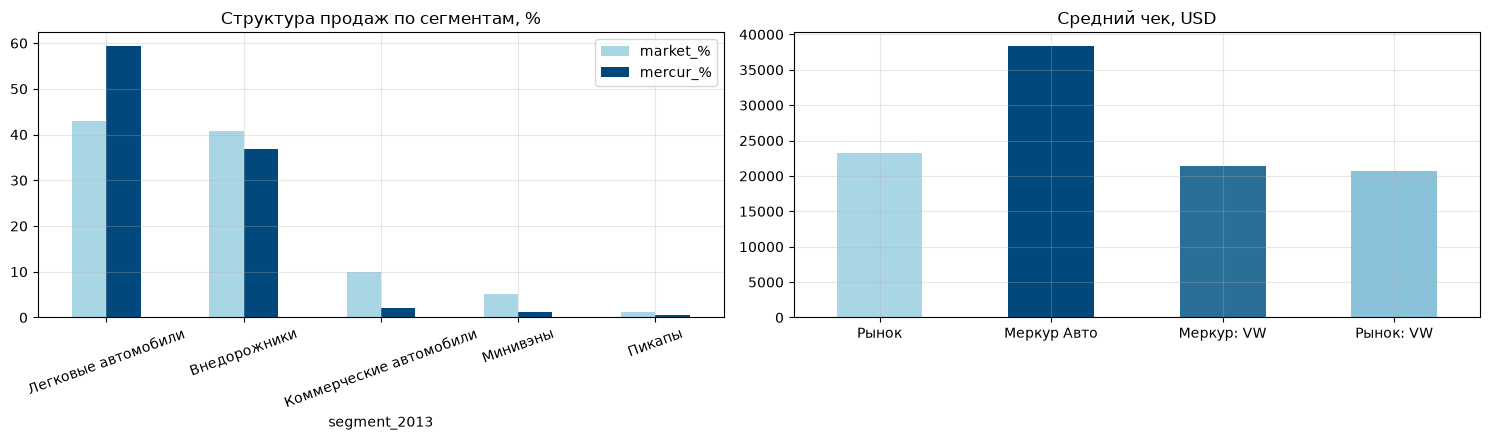

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
compare('segment_2013')[['market_%', 'mercur_%']].plot.bar(ax=ax[0], color=['#a9d6e5', '#01497c'], rot=20); ax[0].set_title('Структура продаж по сегментам, %')
avg = pd.Series({'Рынок': s / q, 'Меркур Авто': ms / mq,
                 'Меркур: VW': m[m.brand == 'Volkswagen'].sale_usd.sum() / m[m.brand == 'Volkswagen'].quantity.sum(),
                 'Рынок: VW': df[df.brand == 'Volkswagen'].sale_usd.sum() / df[df.brand == 'Volkswagen'].quantity.sum()})
avg.plot.bar(ax=ax[1], color=['#a9d6e5', '#01497c', '#2a6f97', '#89c2d9'], rot=0); ax[1].set_title('Средний чек, USD')
plt.tight_layout(); plt.show()

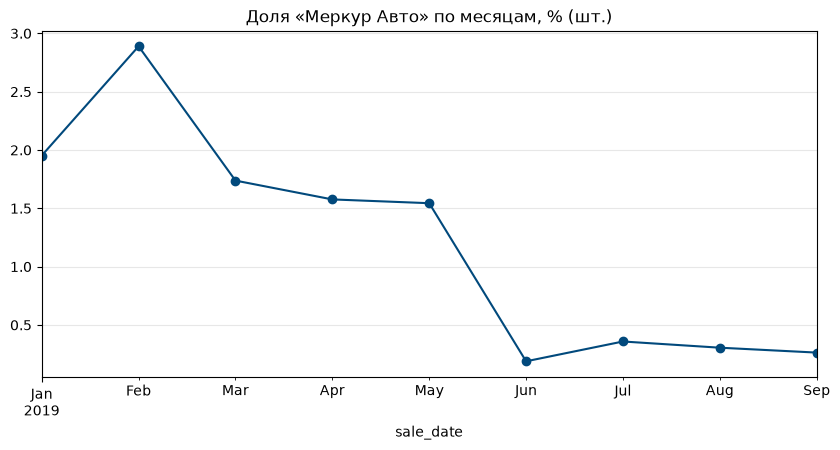

,mercur_units,market_units,share_%
sale_date,,,
2019-01-31,58,2971,1.95
2019-02-28,93,3219,2.89
2019-03-31,62,3568,1.74
2019-04-30,68,4314,1.58
2019-05-31,66,4275,1.54
2019-06-30,8,4246,0.19
2019-07-31,16,4467,0.36
2019-08-31,13,4262,0.31
2019-09-30,10,3802,0.26


In [26]:
mm = pd.DataFrame({'mercur_units': m.groupby('sale_date').quantity.sum(), 'market_units': monthly.units})
mm['share_%'] = mm.mercur_units / mm.market_units * 100
ax = mm['share_%'].plot(marker='o', color='#01497c', title='Доля «Меркур Авто» по месяцам, % (шт.)'); plt.show()
mm

### Выводы
* «Меркур Авто» — 11-е место по выручке среди 33 компаний: 394 шт., 15,1 млн USD, 1,1 % рынка в штуках и 1,9 % в деньгах.
* Средний чек 38,4 тыс. USD — в 1,66 раза выше рынка: премиальный портфель (Porsche и Audi — 100 % продаж этих брендов в данных).
* По Volkswagen доля «Меркур Авто» — 28 % (294 из 1 048 шт.); главный конкурент — Volkswagen Group Rus (в т. ч. оптовые партии Polo).
* Продажи сосредоточены в Алматы (64 % штук, 51 % продаж VW/Audi/Porsche в городе); в Нур-Султане 0,9 % рынка, в Шымкенте нет.
* Слабые места: резкий спад с июня (66 → 8 шт. в месяц), нет дизельных и коммерческих моделей, мало «механики», нет доступных SUV вроде Skoda/Kia.

## 5. Выгрузка

In [27]:
df.to_csv('autokz2019_clean.csv', index=False, encoding='utf-8')
print(df.shape)

(21243, 19)
